# Practice 8 — Decision Making and Classical Machine Learning

### Café lunch demand: probability, decisions, regression, and evaluation

**Student:** Ibragim Mukash


## Aim and objectives

**Aim:** estimate café demand, compare decisions, use simple regression models, and interpret evaluation metrics.

**Objectives**

1. Compute Naive Bayes priors, conditional probabilities, class scores, and normalised posteriors, including absent evidence and Laplace smoothing.
2. Select an action by expected loss and expected utility.
3. Fit and interpret linear and logistic regression models.
4. Evaluate a classifier with accuracy, precision, recall, and F1, and explain the confusion matrix.

## Key formulas

| Concept | Formula |
|---|---|
| Naive Bayes score | $Score(Y) = P(Y)\,P(\text{Cold}=1 \mid Y)\,P(\text{Rain}=1 \mid Y)$ |
| Posterior | $P(\text{High} \mid x) = \dfrac{Score(\text{High})}{Score(\text{High}) + Score(\text{Low})}$ |
| Laplace smoothing | $P(\text{Event}=v \mid \text{Low}) = \dfrac{count(\text{Event}=v,\text{Low}) + 1}{6 + 2}$ |
| Expected loss | $EL(a) = \sum_y P(y)\,L(a,y)$ |
| Expected utility | $EU(a) = \sum_y P(y)\,U(a,y)$ |
| Linear regression | $\hat{y} = wx + b$,  $MSE = \frac{1}{n}\sum_i (y_i - \hat{y}_i)^2$ |
| Logistic regression | $P(\text{High} \mid x) = \sigma(z) = \frac{1}{1 + e^{-z}}$,  $z = w_1x_1 + w_2x_2 + b$ |
| Accuracy | $\frac{TP + TN}{TP + TN + FP + FN}$ |
| Precision | $\frac{TP}{TP + FP}$ |
| Recall | $\frac{TP}{TP + FN}$ |
| F1 | $2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}$ |

## Python setup

The notebook uses NumPy, pandas, scikit-learn, and Matplotlib. These libraries are preinstalled in Google Colab, so no installation is required. The next cell imports them and prints their versions.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from fractions import Fraction

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.float_format", lambda value: f"{value:.4f}")

print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib:", plt.matplotlib.__version__)

numpy: 2.4.6
pandas: 2.2.3
scikit-learn: 1.6.1
matplotlib: 3.10.0


## Task 1 — Naive Bayes by hand

The café predicts **High** demand (at least 40 lunches) or **Low** demand (fewer than 40). Today is cold and rainy: **Cold = 1, Rain = 1**.

| Training count | High | Low |
|---|---:|---:|
| Days | 6 | 6 |
| Cold = 1 | 5 | 2 |
| Rain = 1 | 4 | 1 |

The counts summarise 12 training days. A day may be both cold and rainy. We assume that Cold and Rain are conditionally independent given the demand class.

### Step 1 — Prior probabilities

Divide each class count by the total number of training days.

In [ ]:
n_days = 12
n_high = 6
n_low = 6
cold_high, cold_low = 5, 2
rain_high, rain_low = 4, 1

p_high = Fraction(n_high, n_days)
p_low = Fraction(n_low, n_days)

print(f"P(High) = {n_high}/{n_days} = {p_high} = {float(p_high):.1%}")
print(f"P(Low)  = {n_low}/{n_days} = {p_low} = {float(p_low):.1%}")
print(f"Check: P(High) + P(Low) = {p_high + p_low}")

P(High) = 6/12 = 1/2 = 50.0%
P(Low)  = 6/12 = 1/2 = 50.0%
Check: P(High) + P(Low) = 1


### Step 2 — Conditional probabilities

Each conditional probability is a count inside one class divided by the number of days in that class.

In [ ]:
p_cold_high = Fraction(cold_high, n_high)
p_rain_high = Fraction(rain_high, n_high)
p_cold_low = Fraction(cold_low, n_low)
p_rain_low = Fraction(rain_low, n_low)

conditional_rows = [
    ("P(Cold = 1 | High)", cold_high, n_high, p_cold_high),
    ("P(Rain = 1 | High)", rain_high, n_high, p_rain_high),
    ("P(Cold = 1 | Low)", cold_low, n_low, p_cold_low),
    ("P(Rain = 1 | Low)", rain_low, n_low, p_rain_low),
]

for name, count, total, value in conditional_rows:
    print(f"{name} = {count}/{total} = {float(value):.4f} = {float(value):.1%}")

P(Cold = 1 | High) = 5/6 = 0.8333 = 83.3%
P(Rain = 1 | High) = 4/6 = 0.6667 = 66.7%
P(Cold = 1 | Low) = 2/6 = 0.3333 = 33.3%
P(Rain = 1 | Low) = 1/6 = 0.1667 = 16.7%


### Step 3 — Class scores

Multiply the prior by the two conditional probabilities. The scores are not probabilities yet.

In [ ]:
score_high = p_high * p_cold_high * p_rain_high
score_low = p_low * p_cold_low * p_rain_low

print(f"Score(High) = {p_high} x {p_cold_high} x {p_rain_high} = {score_high} = {float(score_high):.4f}")
print(f"Score(Low)  = {p_low} x {p_cold_low} x {p_rain_low} = {score_low} = {float(score_low):.4f}")

Score(High) = 1/2 x 5/6 x 2/3 = 5/18 = 0.2778
Score(Low)  = 1/2 x 1/3 x 1/6 = 1/36 = 0.0278


### Step 4 — Normalise the scores

Divide each score by the sum of both scores.

In [ ]:
posterior_high = score_high / (score_high + score_low)
posterior_low = score_low / (score_high + score_low)

print(f"P(High | Cold, Rain) = {score_high} / ({score_high} + {score_low}) = {posterior_high} = {float(posterior_high):.1%}")
print(f"P(Low  | Cold, Rain) = {score_low} / ({score_high} + {score_low}) = {posterior_low} = {float(posterior_low):.1%}")
print(f"Sum check: {posterior_high} + {posterior_low} = {posterior_high + posterior_low}")

P(High | Cold, Rain) = 5/18 / (5/18 + 1/36) = 10/11 = 90.9%
P(Low  | Cold, Rain) = 1/36 / (5/18 + 1/36) = 1/11 = 9.1%
Sum check: 10/11 + 1/11 = 1


### Step 5 — Absent evidence: Cold = 1, Rain = 0

An absent feature is still evidence. Use the complement rule: $P(\text{Rain}=0 \mid Y) = 1 - P(\text{Rain}=1 \mid Y)$.

In [ ]:
p_no_rain_high = 1 - p_rain_high
p_no_rain_low = 1 - p_rain_low

score_high_dry = p_high * p_cold_high * p_no_rain_high
score_low_dry = p_low * p_cold_low * p_no_rain_low

posterior_high_dry = score_high_dry / (score_high_dry + score_low_dry)
posterior_low_dry = score_low_dry / (score_high_dry + score_low_dry)

print(f"P(Rain = 0 | High) = 1 - {p_rain_high} = {p_no_rain_high} = {float(p_no_rain_high):.1%}")
print(f"P(Rain = 0 | Low)  = 1 - {p_rain_low} = {p_no_rain_low} = {float(p_no_rain_low):.1%}")
print(f"Score(High) = {p_high} x {p_cold_high} x {p_no_rain_high} = {score_high_dry} = {float(score_high_dry):.4f}")
print(f"Score(Low)  = {p_low} x {p_cold_low} x {p_no_rain_low} = {score_low_dry} = {float(score_low_dry):.4f}")
print(f"P(High | Cold, no Rain) = {posterior_high_dry} = {float(posterior_high_dry):.1%}")
print(f"P(Low  | Cold, no Rain) = {posterior_low_dry} = {float(posterior_low_dry):.1%}")

comparison = pd.DataFrame([
    {
        "Scenario": "Cold = 1, Rain = 1",
        "P(High)": f"{float(posterior_high):.1%}",
        "P(Low)": f"{float(posterior_low):.1%}",
    },
    {
        "Scenario": "Cold = 1, Rain = 0",
        "P(High)": f"{float(posterior_high_dry):.1%}",
        "P(Low)": f"{float(posterior_low_dry):.1%}",
    },
])
display(comparison)

P(Rain = 0 | High) = 1 - 2/3 = 1/3 = 33.3%
P(Rain = 0 | Low)  = 1 - 1/6 = 5/6 = 83.3%
Score(High) = 1/2 x 5/6 x 1/3 = 5/36 = 0.1389
Score(Low)  = 1/2 x 1/3 x 5/6 = 5/36 = 0.1389
P(High | Cold, no Rain) = 1/2 = 50.0%
P(Low  | Cold, no Rain) = 1/2 = 50.0%


,Scenario,P(High),P(Low)
0,"Cold = 1, Rain = 1",90.9%,9.1%
1,"Cold = 1, Rain = 0",50.0%,50.0%


### Step 6 — Laplace smoothing for the new feature Event

A new binary feature **Event** equals 1 on none of the 6 Low-demand days. Add one count to each possible feature value.

In [ ]:
alpha = 1
event_low_count = 0

p_event1_low = Fraction(event_low_count + alpha, n_low + 2)
p_event0_low = Fraction(n_low - event_low_count + alpha, n_low + 2)

print(f"P(Event = 1 | Low) = ({event_low_count} + 1) / (6 + 2) = {p_event1_low} = {float(p_event1_low):.1%}")
print(f"P(Event = 0 | Low) = (6 + 1) / (6 + 2) = {p_event0_low} = {float(p_event0_low):.1%}")
print(f"Sum check: {p_event1_low + p_event0_low}")

P(Event = 1 | Low) = (0 + 1) / (6 + 2) = 1/8 = 12.5%
P(Event = 0 | Low) = (6 + 1) / (6 + 2) = 7/8 = 87.5%
Sum check: 1


The denominator contains **+2** because the feature is binary: one pseudo-count is added for Event = 1 and one for Event = 0. With two possible values, the total added count is 2, so the two smoothed conditional probabilities still sum to 1:

$$P(\text{Event}=1 \mid \text{Low}) = \frac{0+1}{6+2} = 12.5\%, \qquad P(\text{Event}=0 \mid \text{Low}) = \frac{6+1}{6+2} = 87.5\%.$$

**Why a zero probability is a problem.** Naive Bayes multiplies the probabilities. A single zero makes the whole class score zero, no matter how strong the other evidence is. The class can then never receive a non-zero posterior, and in log-space the calculation contains $\log(0)$, which is undefined. Smoothing replaces zero with a small positive probability.

### Answer table

In [ ]:
answer_table = pd.DataFrame([
    ("P(High) and P(Low)", f"{float(p_high):.1%} and {float(p_low):.1%}"),
    ("P(Cold = 1 | High) and P(Rain = 1 | High)", f"{float(p_cold_high):.1%} and {float(p_rain_high):.1%}"),
    ("P(Cold = 1 | Low) and P(Rain = 1 | Low)", f"{float(p_cold_low):.1%} and {float(p_rain_low):.1%}"),
    ("Score(High) and Score(Low)", f"{float(score_high):.4f} and {float(score_low):.4f}"),
    ("P(High | Cold, Rain) and P(Low | Cold, Rain)", f"{float(posterior_high):.1%} and {float(posterior_low):.1%}"),
    ("P(Rain = 0 | High) and P(Rain = 0 | Low)", f"{float(p_no_rain_high):.1%} and {float(p_no_rain_low):.1%}"),
    ("Score(High) and Score(Low) for Cold = 1, Rain = 0", f"{float(score_high_dry):.4f} and {float(score_low_dry):.4f}"),
    ("P(High | Cold, no Rain) and P(Low | Cold, no Rain)", f"{float(posterior_high_dry):.1%} and {float(posterior_low_dry):.1%}"),
    ("P(Event = 1 | Low) with Laplace smoothing", f"{float(p_event1_low):.1%}"),
    ("P(Event = 0 | Low) with Laplace smoothing", f"{float(p_event0_low):.1%}"),
], columns=["Quantity", "Result"])
display(answer_table)

,Quantity,Result
0,P(High) and P(Low),50.0% and 50.0%
1,P(Cold = 1 | High) and P(Rain = 1 | High),83.3% and 66.7%
2,P(Cold = 1 | Low) and P(Rain = 1 | Low),33.3% and 16.7%
3,Score(High) and Score(Low),0.2778 and 0.0278
4,"P(High | Cold, Rain) and P(Low | Cold, Rain)",90.9% and 9.1%
5,P(Rain = 0 | High) and P(Rain = 0 | Low),33.3% and 83.3%
6,"Score(High) and Score(Low) for Cold = 1, Rain = 0",0.1389 and 0.1389
7,"P(High | Cold, no Rain) and P(Low | Cold, no R...",50.0% and 50.0%
8,P(Event = 1 | Low) with Laplace smoothing,12.5%
9,P(Event = 0 | Low) with Laplace smoothing,87.5%


### Interpretation

High demand is more likely on a cold, rainy day: **P(High | Cold, Rain) = 90.9%** against **P(Low | Cold, Rain) = 9.1%**.

- Both features are more frequent among High-demand days: Cold appears on 5 of 6 High days but only 2 of 6 Low days, and Rain appears on 4 of 6 High days but only 1 of 6 Low days.
- The two posterior probabilities sum to 100%.
- Rain is the stronger signal. When rain is removed, the evidence becomes symmetric: $5/6 \times 2/6 = 2/6 \times 5/6$, so the posterior is exactly 50/50. Adding rain raises P(High) from 50.0% to 90.9%.
- The result is an estimate from only 12 training days, not a guarantee about tomorrow.

In [ ]:
assert posterior_high == Fraction(10, 11)
assert posterior_low == Fraction(1, 11)
assert posterior_high + posterior_low == 1
assert posterior_high_dry == posterior_low_dry == Fraction(1, 2)
print("Checks passed: posteriors sum to 1; P(High | Cold, Rain) = 10/11; the dry-day posterior is exactly 1/2.")

Checks passed: posteriors sum to 1; P(High | Cold, Rain) = 10/11; the dry-day posterior is exactly 1/2.


## Task 2 — Expected loss and utility

Use the **unrounded** probability from Task 1: $P(\text{High} \mid \text{Cold}, \text{Rain}) = 10/11$. The two actions are **Extra** (prepare additional lunches) and **Usual** (prepare the usual quantity). Losses are in hypothetical loss units, not lunches.

| Action | Actually High | Actually Low |
|---|---:|---:|
| Extra | 0 | 60 |
| Usual | 30 | 0 |

$$EL(\text{Extra}) = P(\text{High}) \cdot 0 + P(\text{Low}) \cdot 60, \qquad EL(\text{Usual}) = P(\text{High}) \cdot 30 + P(\text{Low}) \cdot 0.$$

In [ ]:
p_high_exact = posterior_high
p_low_exact = posterior_low

el_extra = p_low_exact * 60
el_usual = p_high_exact * 30

print(f"EL(Extra) = P(Low) x 60 = {p_low_exact} x 60 = {el_extra} = {float(el_extra):.2f} loss units")
print(f"EL(Usual) = P(High) x 30 = {p_high_exact} x 30 = {el_usual} = {float(el_usual):.2f} loss units")
print("Selected action (minimum expected loss):", "Extra" if el_extra < el_usual else "Usual")

EL(Extra) = P(Low) x 60 = 1/11 x 60 = 60/11 = 5.45 loss units
EL(Usual) = P(High) x 30 = 10/11 x 30 = 300/11 = 27.27 loss units
Selected action (minimum expected loss): Extra


### Expected utility

Utility equals negative loss. The code below is the function supplied in the guide, with the illustrative 0.90 replaced by the exact Task 1 result.

In [ ]:
p_high_float = float(p_high_exact)
p_low_float = 1 - p_high_float

actions = {
    "Extra": ([p_high_float, p_low_float], [0, -60]),
    "Usual": ([p_high_float, p_low_float], [-30, 0]),
}

def EU(probs, utilities):
    return sum(p * u for p, u in zip(probs, utilities))

scores = {name: EU(*values) for name, values in actions.items()}
print(scores)
print("Selected action (maximum expected utility):", max(scores, key=scores.get))

{'Extra': -5.454545454545457, 'Usual': -27.272727272727273}
Selected action (maximum expected utility): Extra


In [ ]:
task2_table = pd.DataFrame([
    {"Action": "Extra", "Expected loss": f"{float(el_extra):.2f}", "Expected utility": f"{scores['Extra']:.2f}"},
    {"Action": "Usual", "Expected loss": f"{float(el_usual):.2f}", "Expected utility": f"{scores['Usual']:.2f}"},
])
display(task2_table)

print(f"Check EU = -EL for Extra: {scores['Extra']:+.2f} = {-float(el_extra):+.2f}")
print(f"Check EU = -EL for Usual: {scores['Usual']:+.2f} = {-float(el_usual):+.2f}")

,Action,Expected loss,Expected utility
0,Extra,5.45,-5.45
1,Usual,27.27,-27.27


Check EU = -EL for Extra: -5.45 = -5.45
Check EU = -EL for Usual: -27.27 = -27.27


### Decision threshold

With the same loss table, let $p = P(\text{High} \mid x)$. Then $EL(\text{Extra}) = 60(1-p)$ and $EL(\text{Usual}) = 30p$. Extra is better when $60(1-p) < 30p$, that is $p > 60/90 = 66.7\%$.

In [ ]:
threshold = 60 / (60 + 30)

print(f"Decision threshold: p* = 60 / (60 + 30) = {threshold:.3f} = {threshold:.1%}")
print(f"P(High | Cold, Rain) = {float(p_high_exact):.1%} -> {'Extra' if float(p_high_exact) > threshold else 'Usual'}")

Decision threshold: p* = 60 / (60 + 30) = 0.667 = 66.7%
P(High | Cold, Rain) = 90.9% -> Extra


### Answer

- **EL(Extra) = 5.45** loss units; **EL(Usual) = 27.27** loss units. The smaller loss is Extra.
- **EU(Extra) = −5.45**; **EU(Usual) = −27.27**. The larger utility is Extra.
- **Selected action: Extra.**
- For each action, $EU = -EL$: $-5.45 = -5.45$ and $-27.27 = -27.27$. Maximising utility and minimising expected loss therefore give the same choice.
- **Extra does not specify an exact number of additional lunches.** It is only a choice between two actions. The quantity would require a separate decision, for example based on the regression prediction from Task 3A.

## Task 3A — Linear regression

A separate dataset describes café visitors and lunch sales. All demand was satisfied, so observed sales equal demand.

| Visitors x | Actual sales y |
|---:|---:|
| 100 | 29 |
| 150 | 41 |
| 200 | 53 |
| 250 | 66 |
| 300 | 78 |

### Fitted model and prediction for 180 visitors

In [ ]:
visitors = np.array([100, 150, 200, 250, 300])
sales = np.array([29, 41, 53, 66, 78])

X = visitors.reshape(-1, 1)

lin_model = LinearRegression()
lin_model.fit(X, sales)

w = lin_model.coef_[0]
b = lin_model.intercept_

print(f"Slope w     = {w:.3f}")
print(f"Intercept b = {b:.3f}")
print(f"Fitted line: y_hat = {w:.3f} * x + {b:.3f}")

pred_180 = lin_model.predict([[180]])[0]
print(f"Prediction for 180 visitors: {pred_180:.2f} lunches")

Slope w     = 0.246
Intercept b = 4.200
Fitted line: y_hat = 0.246 * x + 4.200
Prediction for 180 visitors: 48.48 lunches


### Residuals and a two-observation MSE

Using the fitted equation, predict the first two observations and compute the residuals.

In [ ]:
pred_100 = lin_model.predict([[100]])[0]
pred_150 = lin_model.predict([[150]])[0]

residual_100 = 29 - pred_100
residual_150 = 41 - pred_150
mse_first_two = (residual_100**2 + residual_150**2) / 2

print(f"x = 100: y_hat = {pred_100:.2f}, residual = 29 - {pred_100:.2f} = {residual_100:+.2f}")
print(f"x = 150: y_hat = {pred_150:.2f}, residual = 41 - {pred_150:.2f} = {residual_150:+.2f}")
print(f"MSE(first two) = [({residual_100:+.2f})^2 + ({residual_150:+.2f})^2] / 2 = {mse_first_two:.4f} lunches^2")

x = 100: y_hat = 28.80, residual = 29 - 28.80 = +0.20
x = 150: y_hat = 41.10, residual = 41 - 41.10 = -0.10
MSE(first two) = [(+0.20)^2 + (-0.10)^2] / 2 = 0.0250 lunches^2


### Candidate models A and B

These are **separate candidate lines**, not the fitted model above. Compare them on the same two observations, $(100, 29)$ and $(150, 41)$.

In [ ]:
def candidate_mse(slope, intercept):
    p100 = slope * 100 + intercept
    p150 = slope * 150 + intercept
    mse = ((29 - p100) ** 2 + (41 - p150) ** 2) / 2
    return p100, p150, mse

rows = []
for name, slope, intercept in [("A: y = 0.20x + 10", 0.20, 10), ("B: y = 0.25x + 5", 0.25, 5)]:
    p100, p150, mse = candidate_mse(slope, intercept)
    rows.append({
        "Candidate": name,
        "Prediction at x = 100": f"{p100:.2f}",
        "Prediction at x = 150": f"{p150:.2f}",
        "MSE": f"{mse:.3f}",
    })

display(pd.DataFrame(rows))

,Candidate,Prediction at x = 100,Prediction at x = 150,MSE
0,A: y = 0.20x + 10,30.00,40.00,1.000
1,B: y = 0.25x + 5,30.00,42.50,1.625


### Visual check

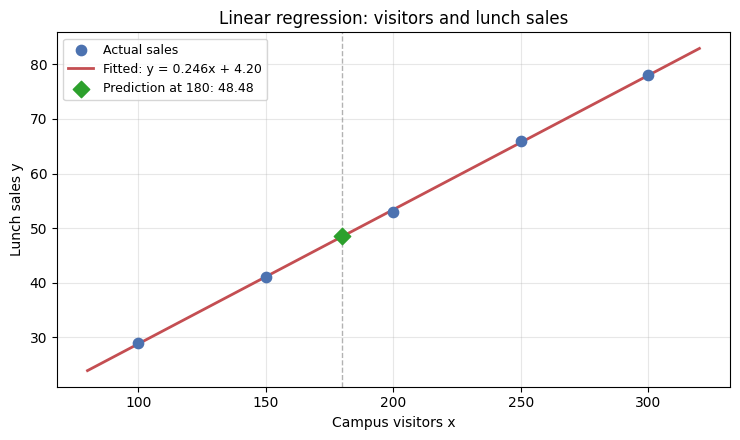

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))

ax.scatter(visitors, sales, color="#4C72B0", s=55, zorder=3, label="Actual sales")
x_line = np.linspace(80, 320, 100)
ax.plot(x_line, w * x_line + b, color="#C44E52", linewidth=2, label=f"Fitted: y = {w:.3f}x + {b:.2f}")
ax.scatter([180], [pred_180], color="#2CA02C", marker="D", s=70, zorder=4, label=f"Prediction at 180: {pred_180:.2f}")
ax.axvline(180, color="gray", linestyle="--", linewidth=1, alpha=0.6)

ax.set_xlabel("Campus visitors x")
ax.set_ylabel("Lunch sales y")
ax.set_title("Linear regression: visitors and lunch sales")
ax.legend(loc="upper left", fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Answer and interpretation

- **Fitted equation:** $\hat{y} = 0.246x + 4.20$.
- **Prediction for 180 visitors:** $0.246 \times 180 + 4.20 = 48.48 \approx 48.5$ **lunches per day**. The unit is lunches, because the target is the number of lunches sold.
- **First two observations:** $\hat{y}_{100} = 28.80$ (residual $+0.20$) and $\hat{y}_{150} = 41.10$ (residual $-0.10$). The two-observation MSE is $[(0.20)^2 + (-0.10)^2]/2 = 0.025$ **lunches²**.
- **Candidates:** A has MSE $= 1.000$ and B has MSE $= 1.625$ on these two points, so A fits the two observations better.
- The MSE unit is **lunches²** because residuals are in lunches and are squared. The value 0.025 describes only the first two observations; it is not the full five-point training MSE and not a test score.
- A small training error does not prove accurate future predictions. The line was fitted to these five days, so it can fit them closely even if demand changes, the sample is small, or the linear form is wrong. Generalisation must be checked on separate validation or test days.

## Task 3B — Logistic regression

Cold and Rain are the two features. The target is 1 for High demand and 0 for Low demand. The 12 training examples match the class and feature counts from Task 1.

The pipeline standardises the two inputs with `StandardScaler` and then fits `LogisticRegression`. Standardisation uses the training means and standard deviations; the model still returns a probability for class 1 (High).

In [ ]:
X_train = np.array([
    [1, 1], [1, 1], [1, 1],
    [1, 0], [1, 0], [0, 1],
    [1, 1], [1, 0], [0, 0],
    [0, 0], [0, 0], [0, 0],
])
y_train = np.array([1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0])
X_test = np.array([[1, 1], [1, 0]])

log_model = make_pipeline(StandardScaler(), LogisticRegression())
log_model.fit(X_train, y_train)

p_high_log = log_model.predict_proba(X_test)[:, 1]
alerts = (p_high_log >= 0.50 - 1e-12).astype(int)  # tolerance: the second case is exactly at 0.5

print("P(High | x):", p_high_log)
print("Predicted labels:", alerts)

task3b = pd.DataFrame({
    "Scenario": ["Cold = 1, Rain = 1", "Cold = 1, Rain = 0"],
    "P(High)": [f"{v:.1%}" for v in p_high_log],
    "P(Low)": [f"{1 - v:.1%}" for v in p_high_log],
    "Predicted label": ["High" if a == 1 else "Low" for a in alerts],
})
display(task3b)

P(High | x): [0.79322589 0.5       ]
Predicted labels: [1 1]


,Scenario,P(High),P(Low),Predicted label
0,"Cold = 1, Rain = 1",79.3%,20.7%,High
1,"Cold = 1, Rain = 0",50.0%,50.0%,High


### Comparison with Naive Bayes

,Scenario,Naive Bayes P(High),Logistic regression P(High)
0,"Cold = 1, Rain = 1",90.9%,79.3%
1,"Cold = 1, Rain = 0",50.0%,50.0%


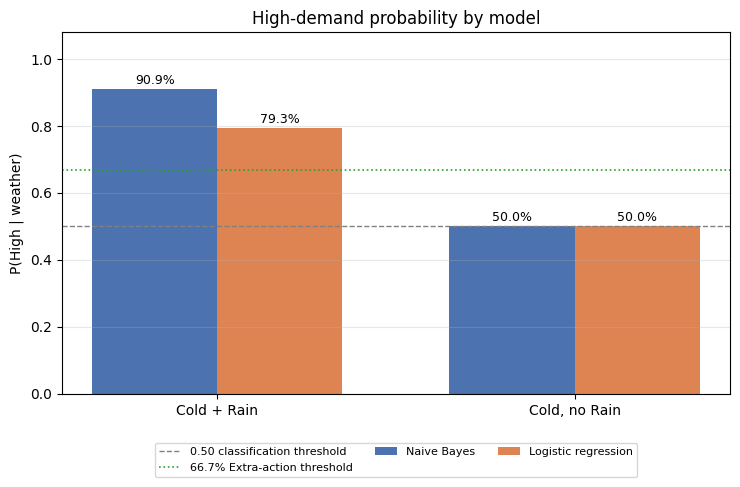

In [ ]:
model_comparison = pd.DataFrame({
    "Scenario": ["Cold = 1, Rain = 1", "Cold = 1, Rain = 0"],
    "Naive Bayes P(High)": [f"{float(posterior_high):.1%}", f"{float(posterior_high_dry):.1%}"],
    "Logistic regression P(High)": [f"{p_high_log[0]:.1%}", f"{p_high_log[1]:.1%}"],
})
display(model_comparison)

scenarios = ["Cold + Rain", "Cold, no Rain"]
nb_values = [float(posterior_high), float(posterior_high_dry)]
lr_values = [p_high_log[0], p_high_log[1]]

x = np.arange(len(scenarios))
width = 0.35

fig, ax = plt.subplots(figsize=(7.5, 5.0))
bars_nb = ax.bar(x - width / 2, nb_values, width, label="Naive Bayes", color="#4C72B0")
bars_lr = ax.bar(x + width / 2, lr_values, width, label="Logistic regression", color="#DD8452")

ax.axhline(0.5, color="gray", linestyle="--", linewidth=1, label="0.50 classification threshold")
ax.axhline(2 / 3, color="#2CA02C", linestyle=":", linewidth=1.2, label="66.7% Extra-action threshold")

ax.set_xticks(x)
ax.set_xticklabels(scenarios)
ax.set_ylim(0, 1.08)
ax.set_ylabel("P(High | weather)")
ax.set_title("High-demand probability by model")
ax.bar_label(bars_nb, labels=[f"{v:.1%}" for v in nb_values], padding=2, fontsize=9)
ax.bar_label(bars_lr, labels=[f"{v:.1%}" for v in lr_values], padding=2, fontsize=9)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=8)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Answer and interpretation

| Scenario | P(High) | Predicted label |
|---|---:|---|
| Cold = 1, Rain = 1 | 79.3% | High |
| Cold = 1, Rain = 0 | 50.0% | High (exactly at the threshold) |

- The cold, rainy day receives **79.3%**, compared with **90.9%** from Naive Bayes in Task 1. Both estimates exceed the 66.7% action threshold, so both recommend Extra. Without rain, both models give **50.0%**, below 66.7%, so both recommend Usual.
- The second input is exactly at the 0.50 threshold. The code applies the rule $p \ge 0.50$ and labels it High, but the model is indifferent between the two classes; a tiny change in the data or in the solver could move it to the other side. This is a boundary case, not a confident prediction.
- **Why the estimates differ.** Naive Bayes multiplies separately estimated conditional probabilities and assumes Cold and Rain are independent given the class. With only 12 days, those frequency estimates are coarse, and multiplying them tends to produce overconfident probabilities. Logistic regression estimates both weights jointly by maximising the likelihood of the observed labels; it can account for correlation between the features and applies regularisation by default, which shrinks the probabilities toward the middle. The two models therefore answer the same question with different assumptions and different estimates.
- **Why logistic regression returns a probability.** It models the log-odds of High demand as a linear function of the features and passes the result through the sigmoid, so the output is always between 0 and 1 and has a probability interpretation. Linear regression predicts the conditional mean of a continuous target directly; its output is an unbounded number in the target's units (lunches), not a probability.
- `X_test` contains two new weather scenarios without true labels. No test accuracy is computed from them.

## Task 4 — Model evaluation by hand

A separate classifier was tested on **60 unseen days**. High is the positive class.

| Prediction / reality | Actually High | Actually Low |
|---|---:|---:|
| Predicted High | TP = 21 | FP = 9 |
| Predicted Low | FN = 3 | TN = 27 |

$Accuracy = \frac{TP+TN}{TP+TN+FP+FN}$, $Precision = \frac{TP}{TP+FP}$, $Recall = \frac{TP}{TP+FN}$.

In [ ]:
TP, FP, FN, TN = 21, 9, 3, 27

accuracy = Fraction(TP + TN, TP + TN + FP + FN)
precision = Fraction(TP, TP + FP)
recall = Fraction(TP, TP + FN)
f1 = 2 * precision * recall / (precision + recall)

print(f"Accuracy  = ({TP} + {TN}) / {TP + TN + FP + FN} = {accuracy} = {float(accuracy):.1%}")
print(f"Precision = {TP} / ({TP} + {FP}) = {precision} = {float(precision):.1%}")
print(f"Recall    = {TP} / ({TP} + {FN}) = {recall} = {float(recall):.1%}")
print(f"F1        = 2 x {precision} x {recall} / ({precision} + {recall}) = {f1} = {float(f1):.1%}")

Accuracy  = (21 + 27) / 60 = 4/5 = 80.0%
Precision = 21 / (21 + 9) = 7/10 = 70.0%
Recall    = 21 / (21 + 3) = 7/8 = 87.5%
F1        = 2 x 7/10 x 7/8 / (7/10 + 7/8) = 7/9 = 77.8%


### What each denominator counts

In [ ]:
metrics_table = pd.DataFrame([
    {
        "Metric": "Accuracy",
        "Formula": "(TP + TN) / (TP + TN + FP + FN)",
        "Denominator counts": f"all {TP + TN + FP + FN} days",
        "Value": f"{float(accuracy):.1%}",
    },
    {
        "Metric": "Precision",
        "Formula": "TP / (TP + FP)",
        "Denominator counts": f"all {TP + FP} days predicted High",
        "Value": f"{float(precision):.1%}",
    },
    {
        "Metric": "Recall",
        "Formula": "TP / (TP + FN)",
        "Denominator counts": f"all {TP + FN} days actually High",
        "Value": f"{float(recall):.1%}",
    },
])
display(metrics_table)

,Metric,Formula,Denominator counts,Value
0,Accuracy,(TP + TN) / (TP + TN + FP + FN),all 60 days,80.0%
1,Precision,TP / (TP + FP),all 30 days predicted High,70.0%
2,Recall,TP / (TP + FN),all 24 days actually High,87.5%


A **false negative** is a day with actually high demand that the classifier labels Low. For the café this means preparing too few lunches: the queue is longer than the stock, some customers are turned away, and sales are lost. This error is often more expensive than a false positive, which leaves leftovers. The FN count is therefore important when choosing a model.

### Train, validation, and test data

| Purpose | Dataset |
|---|---|
| Learn parameters (probabilities or weights) | **Training** |
| Choose settings (for example, smoothing strength) | **Validation** |
| Evaluate the final model on unseen days | **Test** |

### F1 score

F1 combines precision and recall into one number. It is their harmonic mean, so it is high only when both are high: $F1 = 2 \times 0.70 \times 0.875 / (0.70 + 0.875) = 77.8\%$.

### The accuracy trap: a classifier that always predicts Low

A separate example: among 50 days, 45 are Low and 5 are High. The classifier always predicts Low.

In [ ]:
TP_all_low, FP_all_low, FN_all_low, TN_all_low = 0, 0, 5, 45

accuracy_all_low = Fraction(TP_all_low + TN_all_low, 50)
recall_all_low = Fraction(TP_all_low, TP_all_low + FN_all_low)

print(f"Always-Low: TP = {TP_all_low}, FP = {FP_all_low}, FN = {FN_all_low}, TN = {TN_all_low}")
print(f"Accuracy = (0 + 45) / 50 = {accuracy_all_low} = {float(accuracy_all_low):.1%}")
print(f"Recall for High = 0 / (0 + 5) = {recall_all_low} = {float(recall_all_low):.1%}")

Always-Low: TP = 0, FP = 0, FN = 5, TN = 45
Accuracy = (0 + 45) / 50 = 9/10 = 90.0%
Recall for High = 0 / (0 + 5) = 0 = 0.0%


For this classifier, accuracy is 90.0% but recall for High is 0.0%. Accuracy is misleading because 45 of the 50 days belong to the majority class: predicting Low everywhere is enough to be "right" most of the time. The classifier detects none of the 5 High-demand days, which are the days the café most needs to anticipate. Recall, the confusion matrix, and the costs of each error reveal the failure that accuracy hides.

### Confusion matrix visualisation

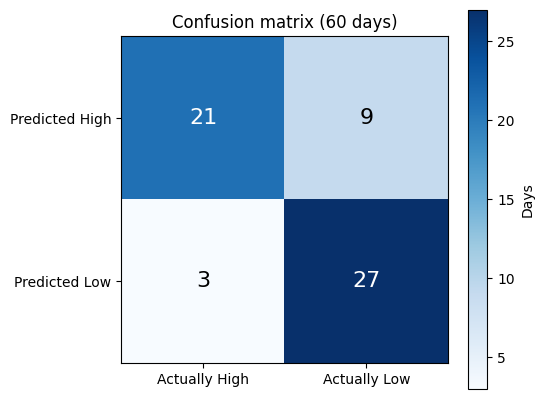

In [ ]:
cm = np.array([[TP, FP], [FN, TN]])

fig, ax = plt.subplots(figsize=(5.5, 4.5))
image = ax.imshow(cm, cmap="Blues")

ax.set_xticks([0, 1])
ax.set_xticklabels(["Actually High", "Actually Low"])
ax.set_yticks([0, 1])
ax.set_yticklabels(["Predicted High", "Predicted Low"])

for i in range(2):
    for j in range(2):
        color = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=16, color=color)

ax.set_title("Confusion matrix (60 days)")
plt.colorbar(image, ax=ax, label="Days")
plt.tight_layout()
plt.show()

### Answer and interpretation

- **Accuracy = 80.0%.** The denominator is all 60 days: 48 of 60 predictions are correct.
- **Precision = 70.0%.** The denominator is the 30 days predicted High: 21 are truly High, 9 are false alarms.
- **Recall = 87.5%.** The denominator is the 24 days actually High: 21 are found, 3 are missed.
- **F1 = 77.8%.** It combines precision and recall with the harmonic mean; a high F1 requires both to be reasonably high.
- The classifier is better at finding High days (87.5%) than at avoiding false alarms (70.0%). For the café, the three false negatives are the most costly errors because they mean under-preparation and lost sales.

## Conclusion

**Prediction is not the same as a decision.** A model produces a probability (Naive Bayes: 90.9%; logistic regression: 79.3%) or a number (linear regression: 48.5 lunches at 180 visitors). A decision combines that output with the consequences of each action. In Task 2 the probability 90.9% is only an input; the action Extra follows from the loss table and the expected-loss calculation.

**Expected utility and expected loss agree.** $EU = -EL$ for both actions, so maximising utility (−5.45 for Extra, −27.27 for Usual) and minimising loss (5.45 versus 27.27) select the same action: **Extra**.

**The models answer different questions.** Naive Bayes and logistic regression estimate a class probability with different assumptions; linear regression estimates a quantity. Their outputs are not interchangeable, and a probability is only useful for a decision when the costs are known.

**Evaluation must match the goal.** Accuracy alone can hide failure on the rare High-demand class, as the always-Low example shows (90.0% accuracy, 0.0% recall). Precision, recall, F1, and the confusion matrix give a fuller picture, and the final model should be checked on unseen days.

**Limitations.** The datasets are small and illustrative: 12 training days, 5 sales observations, and a supplied 60-day test set. The Naive Bayes independence assumption is a simplification. The two-observation MSE is an in-sample check, not a generalisation estimate. The logistic regression's second scenario lies exactly on the decision threshold, so its label is a tie.

### Summary of results

In [ ]:
summary = pd.DataFrame([
    ("1. Naive Bayes", "P(High | Cold, Rain) = 90.9%; P(High | Cold, no Rain) = 50.0%; P(Event = 1 | Low) = 12.5% with smoothing"),
    ("2. Expected loss", "EL(Extra) = 5.45, EL(Usual) = 27.27; EU = -5.45 and -27.27; action = Extra"),
    ("3A. Linear regression", "y = 0.246x + 4.20; 48.48 lunches at 180 visitors; two-observation MSE = 0.025"),
    ("3B. Logistic regression", "P(High | Cold, Rain) = 79.3%; P(High | Cold, no Rain) = 50.0%; both labels High"),
    ("4. Evaluation", "Accuracy 80.0%, precision 70.0%, recall 87.5%, F1 77.8%; always-Low: 90.0% accuracy, 0.0% recall"),
], columns=["Task", "Key result"])
display(summary)

,Task,Key result
0,1. Naive Bayes,"P(High | Cold, Rain) = 90.9%; P(High | Cold, n..."
1,2. Expected loss,"EL(Extra) = 5.45, EL(Usual) = 27.27; EU = -5.4..."
2,3A. Linear regression,y = 0.246x + 4.20; 48.48 lunches at 180 visito...
3,3B. Logistic regression,"P(High | Cold, Rain) = 79.3%; P(High | Cold, n..."
4,4. Evaluation,"Accuracy 80.0%, precision 70.0%, recall 87.5%,..."
